## Data Workflow

Creating requirements txt before run

In [1]:
import sys
import json
import random
from pathlib import Path

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.clean import *
from src.validate import *
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

requirements = [
    f"pandas=={pd.__version__}",
    f"numpy=={np.__version__}",
    f"matplotlib=={mpl.__version__}"
]

(PROJECT_ROOT / "configs" / "requirements.txt").write_text("\n".join(requirements) + "\n")
print((PROJECT_ROOT / "configs" / "requirements.txt").read_text())

pandas==3.0.5
numpy==2.5.3
matplotlib==3.11.2



Project env setup

In [2]:

config_path = PROJECT_ROOT / "configs" / "config.json"
with open(config_path) as f:
    config = json.load(f)

DATA_RAW       = PROJECT_ROOT / config["raw"]
DATA_INTERIM   = PROJECT_ROOT / config["interim"]
DATA_PROCESSED = PROJECT_ROOT / config["processed"]
REPORTS        = PROJECT_ROOT / config["reports"]

SEED = config["seed"]
random.seed(SEED)
np.random.seed(SEED)

print("Config loaded:", json.dumps(config, indent=2))
PROJECT_ROOT

Config loaded: {
  "seed": 42,
  "raw_csv": "f1_results.csv",
  "date_format": "%Y-%m-%d",
  "raw": "data/raw",
  "interim": "data/interim",
  "processed": "data/processed",
  "reports": "reports"
}


WindowsPath('C:/Users/Balint/School/IntroToDS/Project')

Importing raw data and displaying it (head)

In [3]:
raw_csv_path = DATA_RAW / config["raw_csv"]
df = pd.read_csv(raw_csv_path)
print("Loaded:", raw_csv_path)
print("Shape:", df.shape)
df.head(10)

Loaded: C:\Users\Balint\School\IntroToDS\Project\data\raw\f1_results.csv
Shape: (25939, 15)


,season,round,race_name,driver_id,driver_name,constructor_id,constructor,grid,position,points,laps,status,time,fastest_lap,fastest_lap_rank
0,1950,1,British Grand Prix,farina,Nino Farina,alfa,Alfa Romeo,1,1,9.0,70,Finished,2:13:23.600,NaN,NaN
1,1950,1,British Grand Prix,fagioli,Luigi Fagioli,alfa,Alfa Romeo,2,2,6.0,70,Finished,+2.600,NaN,NaN
2,1950,1,British Grand Prix,reg_parnell,Reg Parnell,alfa,Alfa Romeo,4,3,4.0,70,Finished,+52.000,NaN,NaN
3,1950,1,British Grand Prix,cabantous,Yves Cabantous,lago,Talbot-Lago,6,4,3.0,68,+2 Laps,NaN,NaN,NaN
4,1950,1,British Grand Prix,rosier,Louis Rosier,lago,Talbot-Lago,9,5,2.0,68,+2 Laps,NaN,NaN,NaN
5,1950,1,British Grand Prix,gerard,Bob Gerard,era,ERA,13,6,0.0,67,+3 Laps,NaN,NaN,NaN
6,1950,1,British Grand Prix,harrison,Cuth Harrison,era,ERA,15,7,0.0,67,+3 Laps,NaN,NaN,NaN
7,1950,1,British Grand Prix,etancelin,Philippe Étancelin,lago,Talbot-Lago,14,8,0.0,65,+5 Laps,NaN,NaN,NaN
8,1950,1,British Grand Prix,hampshire,David Hampshire,maserati,Maserati,16,9,0.0,64,+6 Laps,NaN,NaN,NaN
9,1950,1,British Grand Prix,fry,Joe Fry,maserati,Maserati,20,10,0.0,64,+6 Laps,NaN,NaN,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   season            25939 non-null  int64  
 1   round             25939 non-null  int64  
 2   race_name         25939 non-null  str    
 3   driver_id         25939 non-null  str    
 4   driver_name       25939 non-null  str    
 5   constructor_id    25939 non-null  str    
 6   constructor       25939 non-null  str    
 7   grid              25939 non-null  int64  
 8   position          25939 non-null  int64  
 9   points            25939 non-null  float64
 10  laps              25939 non-null  int64  
 11  status            25939 non-null  str    
 12  time              8354 non-null   str    
 13  fastest_lap       8785 non-null   str    
 14  fastest_lap_rank  8785 non-null   float64
dtypes: float64(2), int64(5), str(8)
memory usage: 3.0 MB


In [5]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})

,missing_count,missing_pct
time,17585,67.79
fastest_lap,17154,66.13
fastest_lap_rank,17154,66.13
driver_id,0,0.00
season,0,0.00
round,0,0.00
race_name,0,0.00
constructor,0,0.00
constructor_id,0,0.00
driver_name,0,0.00


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Clean

In [7]:
cleanDF = CleanF1Results(df)
cleanDF = cleanDF.drop_duplicates(subset=["season", "round", "driver_id"], keep="first").reset_index(drop=True)
cleanDF.info()

<class 'pandas.DataFrame'>
RangeIndex: 25850 entries, 0 to 25849
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   season            25850 non-null  int64  
 1   round             25850 non-null  int64  
 2   race_name         25850 non-null  str    
 3   driver_id         25850 non-null  str    
 4   driver_name       25850 non-null  str    
 5   constructor_id    25850 non-null  str    
 6   constructor       25850 non-null  str    
 7   grid              25850 non-null  Int64  
 8   position          25850 non-null  Int64  
 9   points            25850 non-null  float64
 10  laps              25850 non-null  Int64  
 11  status            25850 non-null  str    
 12  time              8354 non-null   str    
 13  fastest_lap       8785 non-null   str    
 14  fastest_lap_rank  8785 non-null   Int64  
 15  finished          25850 non-null  bool   
dtypes: Int64(4), bool(1), float64(1), int64(2), str(8)


In [8]:
cleanDF.head(10)

,season,round,race_name,driver_id,driver_name,constructor_id,constructor,grid,position,points,laps,status,time,fastest_lap,fastest_lap_rank,finished
0,1950,1,British Grand Prix,farina,Nino Farina,alfa,Alfa Romeo,1,1,9.0,70,Finished,2:13:23.600,NaN,<NA>,True
1,1950,1,British Grand Prix,fagioli,Luigi Fagioli,alfa,Alfa Romeo,2,2,6.0,70,Finished,+2.600,NaN,<NA>,True
2,1950,1,British Grand Prix,reg_parnell,Reg Parnell,alfa,Alfa Romeo,4,3,4.0,70,Finished,+52.000,NaN,<NA>,True
3,1950,1,British Grand Prix,cabantous,Yves Cabantous,lago,Talbot-Lago,6,4,3.0,68,+2 Laps,NaN,NaN,<NA>,False
4,1950,1,British Grand Prix,rosier,Louis Rosier,lago,Talbot-Lago,9,5,2.0,68,+2 Laps,NaN,NaN,<NA>,False
5,1950,1,British Grand Prix,gerard,Bob Gerard,era,ERA,13,6,0.0,67,+3 Laps,NaN,NaN,<NA>,False
6,1950,1,British Grand Prix,harrison,Cuth Harrison,era,ERA,15,7,0.0,67,+3 Laps,NaN,NaN,<NA>,False
7,1950,1,British Grand Prix,etancelin,Philippe Étancelin,lago,Talbot-Lago,14,8,0.0,65,+5 Laps,NaN,NaN,<NA>,False
8,1950,1,British Grand Prix,hampshire,David Hampshire,maserati,Maserati,16,9,0.0,64,+6 Laps,NaN,NaN,<NA>,False
9,1950,1,British Grand Prix,fry,Joe Fry,maserati,Maserati,20,10,0.0,64,+6 Laps,NaN,NaN,<NA>,False


Validation (non-negatives, req IDs, unique IDs)

In [9]:
ValidateDataframe(
    cleanDF,
    non_negative_cols=["points"],
    required_cols=["driver_id", "constructor_id"],
    unique_key_cols=["season", "round", "driver_id"],
)

Write interim

In [10]:
interim_path = DATA_INTERIM / "f1_results_interim.csv"
cleanDF.to_csv(interim_path, index=False)
print("Wrote:", interim_path)

Wrote: C:\Users\Balint\School\IntroToDS\Project\data\interim\f1_results_interim.csv


Write processed **(not final yet)**

In [11]:
processed_path = DATA_PROCESSED / "f1_results_processed.csv"
cleanDF.to_csv(processed_path, index=False)
print("Wrote:", processed_path)

Wrote: C:\Users\Balint\School\IntroToDS\Project\data\processed\f1_results_processed.csv


Make summary

In [12]:
summary = (
    cleanDF
    .groupby(["season", "constructor"])
    .agg(
        total_points=("points", "sum"),
        races=("round", "nunique"),
        finishes=("finished", "sum"),
        avg_grid=("grid", "mean"),
    )
    .reset_index()
    .sort_values(["season", "total_points"], ascending=[True, False])
    .reset_index(drop=True)
)

summary["avg_grid"] = summary["avg_grid"].round(2)

summary_path = REPORTS / "summary_table.csv"
summary.to_csv(summary_path, index=False)
print("Wrote:", summary_path)
summary.head(15)

Wrote: C:\Users\Balint\School\IntroToDS\Project\reports\summary_table.csv


,season,constructor,total_points,races,wins,avg_grid
0,1950,Alfa Romeo,88.0,6,13,2.95
1,1950,Ferrari,21.0,5,2,10.64
2,1950,Talbot-Lago,20.0,6,1,11.31
3,1950,Kurtis Kraft,14.0,1,1,14.2
4,1950,Maserati,11.0,7,0,14.26
5,1950,Deidt,10.0,1,0,6.5
6,1950,Simca,3.0,3,0,11.6
7,1950,Adams,0.0,1,0,17.0
8,1950,Alta,0.0,2,0,16.0
9,1950,Cooper,0.0,1,0,20.0


In [13]:
print("Columns:", list(cleanDF.columns))
pointsCol = cleanDF["points"]
print("Missing points:", pointsCol.isna().sum())
print("Negative points:", (pointsCol < 0).sum())
print("Data type:", pointsCol.dtype)

Columns: ['season', 'round', 'race_name', 'driver_id', 'driver_name', 'constructor_id', 'constructor', 'grid', 'position', 'points', 'laps', 'status', 'time', 'fastest_lap', 'fastest_lap_rank', 'finished']
Missing points: 0
Negative points: 0
Data type: float64


In [14]:


q25 = pointsCol.quantile(0.25)
q75 = pointsCol.quantile(0.75)
iqr = q75 - q25

summary_points = pd.DataFrame({
    "Metric": ["count", "min", "max", "mean", "median", "std", "IQR"],
    "Value": [
        pointsCol.count(),
        pointsCol.min(),
        pointsCol.max(),
        round(pointsCol.mean(), 3),
        pointsCol.median(),
        round(pointsCol.std(), 3),
        round(iqr, 3)
    ]
})
summary_points

,Metric,Value
0,count,25850.000
1,min,0.000
2,max,50.000
3,mean,2.163
4,median,0.000
5,std,4.541
6,IQR,2.000


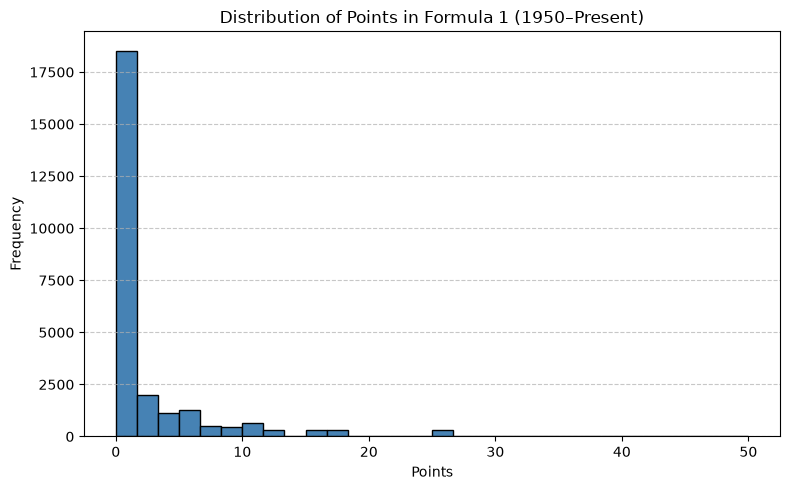

In [15]:
plt.figure(figsize=(8, 5))
plt.hist(pointsCol, bins=30, edgecolor="black", color="steelblue")
plt.title("Distribution of Points in Formula 1 (1950–Present)")
plt.xlabel("Points")
plt.ylabel("Frequency")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

### Summary & Conclusion

The participants in this dataset receive 0.0 points for a typical race entry as the first quartile and the median are both 0.0. The reason for this is that the Formula 1 scoring systems only award points to the competitors who finish in the highest positions. In this data 67.5% of all entries receive no points. The distribution of those numbers is concentrated on the low end with a long tail toward higher values. The mean value of 2.16 is higher than the median. There is a small interquartile range from 0 - 2 which indicates that the middle 50 % of race results frequently include zero points. It is common to see scores of 25 rather than rare because the regulations since 2010 establish 25 points as the standard reward for winning a single race. And the dataset contains 293 instances of this specific score. The single score of 50 is a statistical outlier that Lewis Hamilton earned at the 2014 Abu Dhabi Grand Prix - this was the only event where officials applied a rule to double the points. Because of this asymmetrical distribution, the median and interquartile range describe a "normal" result more accurately than the average.